In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay)

In [2]:
df = pd.read_csv("/content/creditcard.csv")

In [3]:
df.head()
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
13949,24754,1.252924,-0.182189,-0.802716,-0.210981,1.916713,3.643624,-0.778711,0.818295,1.706962,...,-0.497088,-1.211285,0.043809,0.964159,0.442030,0.261483,-0.051402,0.005112,23.74,0.0
13950,24756,-0.346979,-2.103284,-0.685061,1.961605,-0.401125,0.473632,1.133816,-0.256528,0.893409,...,0.359662,-0.316275,-0.864259,-0.279881,0.491802,-0.353996,-0.149931,0.129795,794.20,0.0
13951,24759,-6.053652,-5.988723,0.810413,-0.011811,1.308135,-0.590803,-0.725838,-0.234840,1.624646,...,-0.771970,1.474668,3.176363,-0.302410,0.052529,-0.373871,-0.700463,2.508443,60.00,0.0
13952,24759,1.169121,-1.284945,0.032717,-0.681670,0.660598,4.412578,-1.913115,1.076592,1.501230,...,-0.557596,-0.882435,-0.041523,0.975445,0.297229,0.550515,0.015029,0.032067,90.00,0.0
13953,24759,-6.917152,5.854171,-1.652458,-1.488884,-0.833891,-0.344418,0.393789,0.379968,6.133597,...,-1.404681,-1.124694,0.174333,-0.528234,0.990685,-0.035875,1.071374,-0.168831,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13954 entries, 0 to 13953
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    13954 non-null  int64  
 1   V1      13954 non-null  float64
 2   V2      13954 non-null  float64
 3   V3      13954 non-null  float64
 4   V4      13954 non-null  float64
 5   V5      13954 non-null  float64
 6   V6      13954 non-null  float64
 7   V7      13954 non-null  float64
 8   V8      13954 non-null  float64
 9   V9      13954 non-null  float64
 10  V10     13954 non-null  float64
 11  V11     13954 non-null  float64
 12  V12     13954 non-null  float64
 13  V13     13954 non-null  float64
 14  V14     13954 non-null  float64
 15  V15     13954 non-null  float64
 16  V16     13954 non-null  float64
 17  V17     13954 non-null  float64
 18  V18     13954 non-null  float64
 19  V19     13954 non-null  float64
 20  V20     13954 non-null  float64
 21  V21     13954 non-null  float64
 22

In [5]:
df.shape

(13954, 31)

In [6]:
df.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [7]:
print("Categories:" , df["Class"].unique())

Categories: [ 0.  1. nan]


In [8]:
print("Category counts:")
print(df["Class"].value_counts())

Category counts:
Class
0.0    13897
1.0       56
Name: count, dtype: int64


In [9]:
print("Category percentage:")
print(df["Class"].value_counts(normalize=True)*100)

Category percentage:
Class
0.0    99.598653
1.0     0.401347
Name: proportion, dtype: float64


In [10]:
x = df.drop("Class", axis=1)
y = df["Class"]

print("Feature shape:" , x.shape)
print("Target shape:" , y.shape)

print("\nFeatures:")
print(x.columns.tolist())

Feature shape: (13954, 30)
Target shape: (13954,)

Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [11]:
df_clean = df.dropna()

x = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

print("Cleaned dataset shapes:")
print("Feature shape:", x.shape)
print("Target shape:", y.shape)

Cleaned dataset shapes:
Feature shape: (13953, 30)
Target shape: (13953,)


In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

print("\nFraud cases in training data:", int(y_train.sum()))
print("Fraud cases in testing data:", int(y_test.sum()))

Training data: (11162, 30)
Testing data: (2791, 30)

Fraud cases in training data: 45
Fraud cases in testing data: 11


In [15]:
model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest model...")

model.fit(x_train, y_train)

print("Model training completed successfully!")

Training Random Forest model...
Model training completed successfully!


In [18]:
y_pred = model.predict(x_test)
y_prob = model.predict_proba(x_test)[:, 1]

print("Actual labels:")
print(y_test.head(20))

print("Predicted labels:")
print(y_pred[:20])


Actual labels:
4169     0.0
13838    0.0
9898     0.0
3176     0.0
6756     0.0
9804     0.0
7215     0.0
1333     0.0
8456     0.0
12010    0.0
1167     0.0
12251    0.0
8012     0.0
5489     0.0
5241     0.0
6991     0.0
4833     0.0
6502     0.0
806      0.0
1587     0.0
Name: Class, dtype: float64
Predicted labels:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Confusion Matrix:
[[2780    0]
 [   1   10]]


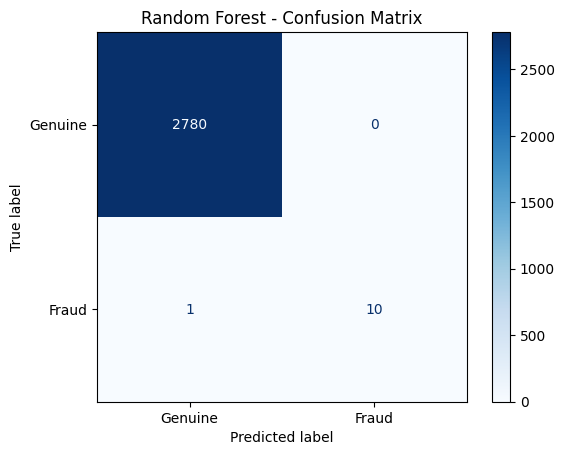

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [20]:
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

MODEL EVALUATION RESULTS
------------------------
Precision : 1.0000
Recall    : 0.9091
F1-score  : 0.9524
ROC-AUC   : 0.9534

Detailed Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00      2780
       Fraud       1.00      0.91      0.95        11

    accuracy                           1.00      2791
   macro avg       1.00      0.95      0.98      2791
weighted avg       1.00      1.00      1.00      2791



In [22]:
results = x_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["Fraud_Probability"] = y_prob

actual_fraud = results[results["Actual"] == 1]

print("Total actual fraud cases:", len(actual_fraud))
print(actual_fraud[["Time", "Amount", "Actual", "Predicted", "Fraud_Probability"]].head(20))

print("Fraud detected:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 1)]))
print("Fraud missed:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 0)]))

actual_fraud.to_csv("actual_fraudulent_test_transactions.csv", index=True)
print("File saved successfully!")


Total actual fraud cases: 11
        Time  Amount  Actual  Predicted  Fraud_Probability
10891  18675  188.78     1.0        1.0               0.78
11841  20332    1.00     1.0        1.0               0.96
6446    7672    1.00     1.0        1.0               0.94
8617   11635    1.00     1.0        1.0               0.84
11710  20011    1.00     1.0        1.0               0.97
6820    8614    1.00     1.0        1.0               0.98
10498  17230    3.93     1.0        0.0               0.00
8335   11131    1.00     1.0        1.0               0.80
12108  21046    1.00     1.0        1.0               0.88
8296   11080    1.00     1.0        1.0               0.55
12369  21662    1.00     1.0        1.0               0.63
Fraud detected: 10
Fraud missed: 1
File saved successfully!


Top 10 Important Features:
V14    0.195078
V4     0.114375
V3     0.112191
V12    0.109074
V10    0.077243
V17    0.073238
V2     0.065951
V11    0.064501
V16    0.034988
V9     0.029221
dtype: float64


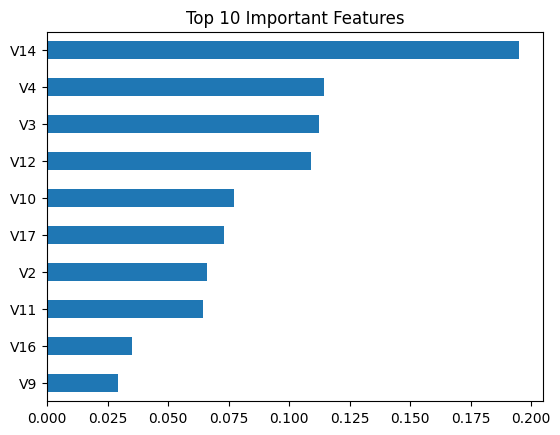

In [24]:
importance = pd.Series(model.feature_importances_, index=x.columns)

top10 = importance.nlargest(10)
print("Top 10 Important Features:")
print(top10)

top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()


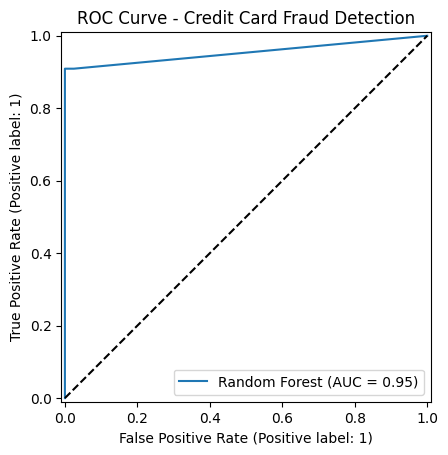

In [25]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.title("ROC Curve - Credit Card Fraud Detection")
plt.plot([0, 1], [0, 1], "k--")
plt.show()